<a href="https://colab.research.google.com/github/sabascodes/Data_mining/blob/main/Copy_of_Data_mining_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
eswarchandt_phishing_website_detector_path = kagglehub.dataset_download('eswarchandt/phishing-website-detector')

print('Data source import complete.')


100%|██████████| 197k/197k [00:00<00:00, 35.7MB/s]

Extracting files...
Data source import complete.


In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv(f"{eswarchandt_phishing_website_detector_path}/phishing.csv")

In [4]:
df.head()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


In [5]:
df.columns

Index(['Index', 'UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//',
       'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon',
       'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL',
       'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL',
       'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick',
       'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage',
       'StatsReport', 'class'],
      dtype='object')

In [6]:
df.shape

(11054, 32)

In [7]:
df.isnull().sum()

,0
Index,0
UsingIP,0
LongURL,0
ShortURL,0
Symbol@,0
Redirecting//,0
PrefixSuffix-,0
SubDomains,0
HTTPS,0
DomainRegLen,0


In [8]:
from sklearn.model_selection import train_test_split,cross_val_score

In [9]:
X= df.drop(columns=['class', 'Index'])
X.head()

,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport
0,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
1,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
2,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
3,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1
4,-1,0,-1,1,-1,-1,1,1,-1,1,...,1,1,1,1,1,1,-1,1,-1,-1


In [10]:
Y=df['class']

In [11]:
train_X,test_X,train_Y,test_Y=train_test_split(X,Y,test_size=0.3,random_state=42, stratify=Y)

In [12]:
print(train_X.shape)
print(test_X.shape)
print(train_Y.shape)
print(test_Y.shape)

(7737, 30)
(3317, 30)
(7737,)
(3317,)


Lets apply Logistic Regression and check its accuracy

In [13]:
from sklearn.linear_model import LogisticRegression
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [14]:
logreg=LogisticRegression(max_iter=2000)
model_1=logreg.fit(train_X,train_Y)

In [15]:
logreg_predict= model_1.predict(test_X)

In [16]:
accuracy_score(test_Y, logreg_predict)

0.9400060295447694

In [17]:
print(classification_report(test_Y,logreg_predict))

              precision    recall  f1-score   support

          -1       0.94      0.93      0.93      1469
           1       0.94      0.95      0.95      1848

    accuracy                           0.94      3317
   macro avg       0.94      0.94      0.94      3317
weighted avg       0.94      0.94      0.94      3317



In [18]:
def plot_confusion_matrix(test_Y, predict_y):
 C = confusion_matrix(test_Y, predict_y)
 A =(((C.T)/(C.sum(axis=1))).T)
 B =(C/C.sum(axis=0))
 plt.figure(figsize=(20,4))
 labels = [-1,1]
 cmap=sns.light_palette("blue")
 plt.subplot(1, 3, 1)
 sns.heatmap(C, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
 plt.xlabel('Predicted Class')
 plt.ylabel('Original Class')
 plt.title("Confusion matrix")
 plt.subplot(1, 3, 2)
 sns.heatmap(B, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
 plt.xlabel('Predicted Class')
 plt.ylabel('Original Class')
 plt.title("Precision matrix")
 plt.subplot(1, 3, 3)
 sns.heatmap(A, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
 plt.xlabel('Predicted Class')
 plt.ylabel('Original Class')
 plt.title("Recall matrix")
 plt.show()

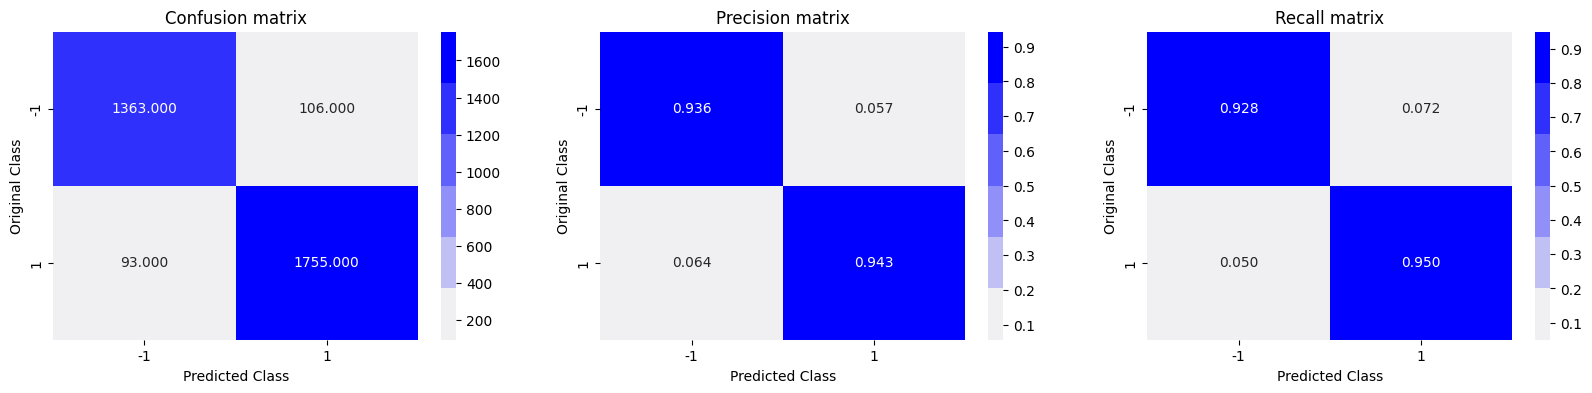

In [19]:
plot_confusion_matrix(test_Y, logreg_predict)

Lets apply K-Nearest Neighbors Classifier and check its accuracy




In [20]:
from sklearn.neighbors import KNeighborsClassifier

In [21]:
knn=KNeighborsClassifier(n_neighbors=3)
model_2= knn.fit(train_X,train_Y)

In [22]:
knn_predict=model_2.predict(test_X)

In [23]:
accuracy_score(knn_predict,test_Y)

0.9445281881217968

In [24]:
print(classification_report(test_Y,knn_predict))

              precision    recall  f1-score   support

          -1       0.94      0.94      0.94      1469
           1       0.95      0.95      0.95      1848

    accuracy                           0.94      3317
   macro avg       0.94      0.94      0.94      3317
weighted avg       0.94      0.94      0.94      3317



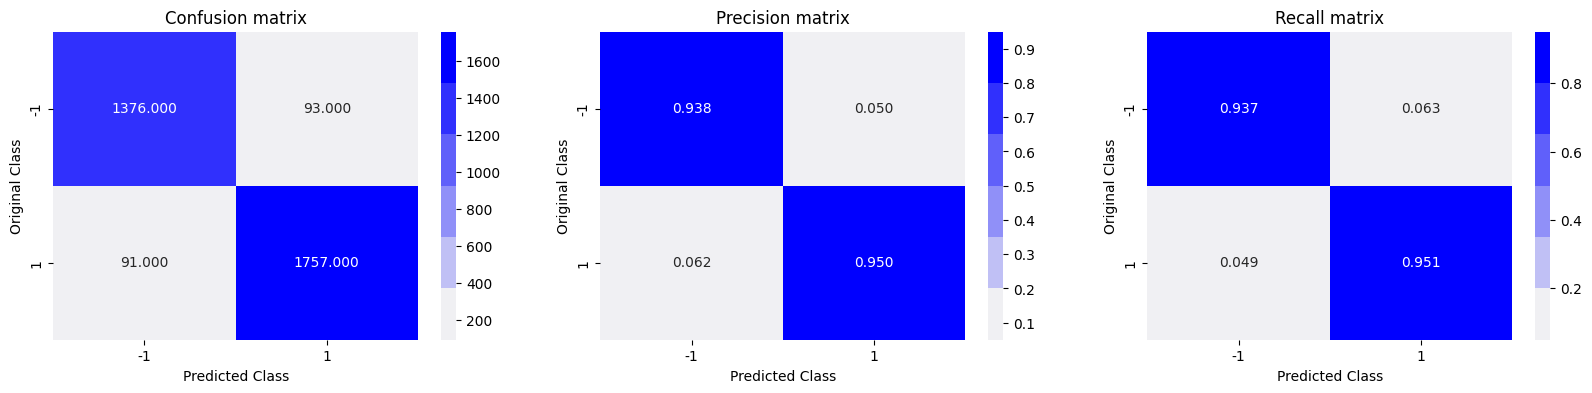

In [25]:
plot_confusion_matrix(test_Y, knn_predict)

**Lets apply Decision Tree Classifier and check its classifier **

In [26]:
from sklearn.tree import DecisionTreeClassifier

In [27]:
dtree=DecisionTreeClassifier(random_state=42)
model_3=dtree.fit(train_X,train_Y)

In [28]:
dtree_predict=model_3.predict(test_X)

In [29]:
accuracy_score(test_Y, dtree_predict)

0.9602050045221586

In [30]:
print(classification_report(test_Y, dtree_predict))

              precision    recall  f1-score   support

          -1       0.95      0.96      0.96      1469
           1       0.97      0.96      0.96      1848

    accuracy                           0.96      3317
   macro avg       0.96      0.96      0.96      3317
weighted avg       0.96      0.96      0.96      3317



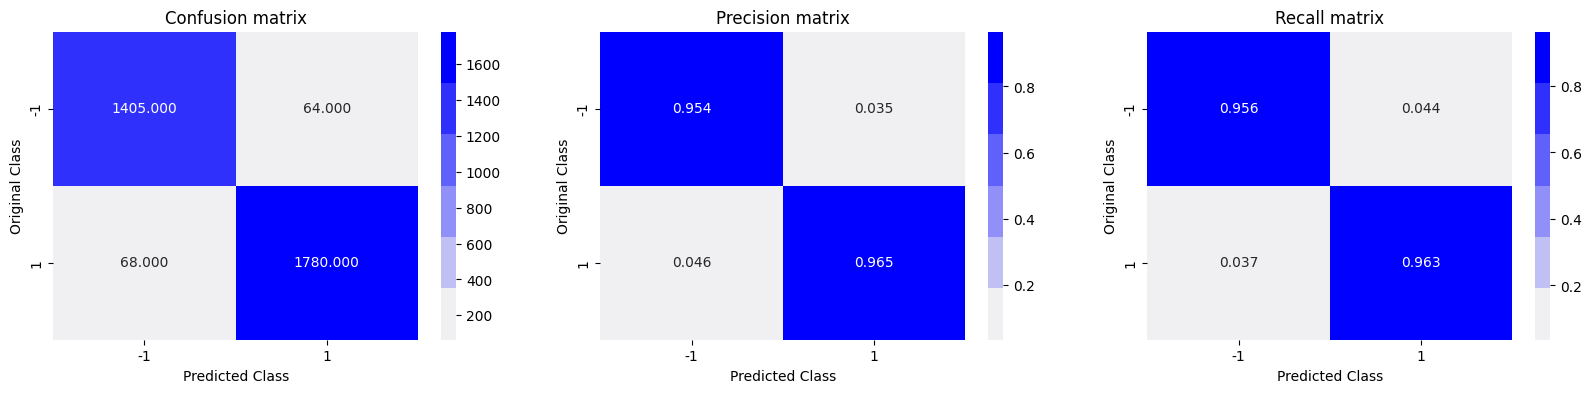

In [31]:
plot_confusion_matrix(test_Y, dtree_predict)

Lets apply Random Forest Classifier and check its accuracy

In [32]:
from sklearn.ensemble import RandomForestClassifier


In [33]:
rfc=RandomForestClassifier(random_state=42)
model_4=rfc.fit(train_X,train_Y)

In [34]:
rfc_predict=model_4.predict(test_X)

In [35]:
accuracy_score(test_Y, rfc_predict)

0.9734700030147724

In [36]:
print(classification_report(test_Y,rfc_predict))

              precision    recall  f1-score   support

          -1       0.98      0.96      0.97      1469
           1       0.97      0.98      0.98      1848

    accuracy                           0.97      3317
   macro avg       0.97      0.97      0.97      3317
weighted avg       0.97      0.97      0.97      3317



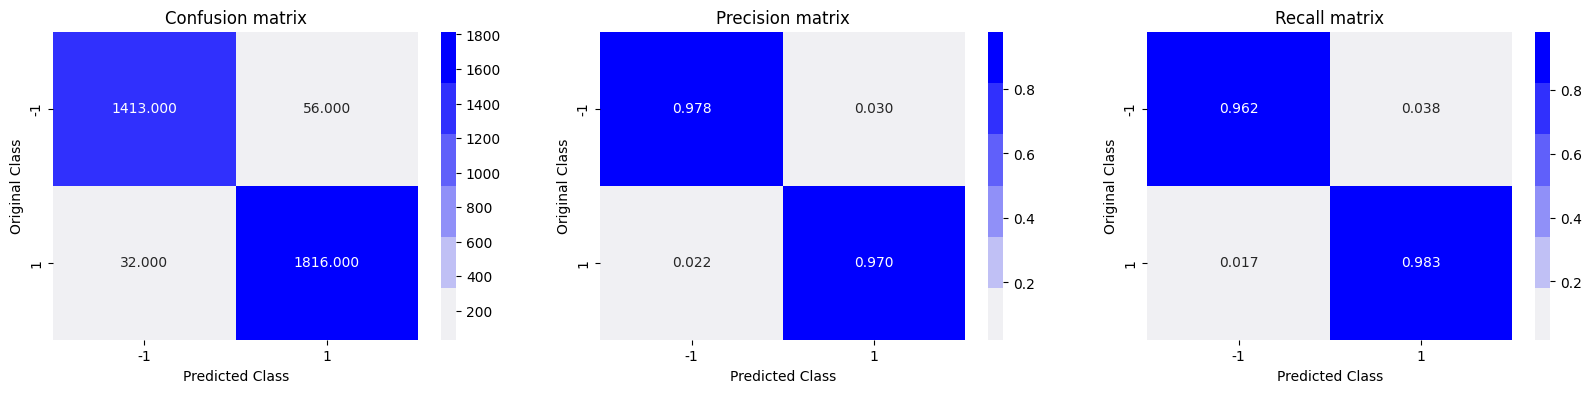

In [37]:
plot_confusion_matrix(test_Y, rfc_predict)

**Lets apply AdaBoost Classifier and check its accuracy **



In [38]:
from sklearn.ensemble import AdaBoostClassifier

In [39]:
adc=AdaBoostClassifier(n_estimators=5,learning_rate=1,random_state=42)
model_6=adc.fit(train_X,train_Y)

In [40]:
adc_predict=model_6.predict(test_X)

In [41]:
accuracy_score(adc_predict,test_Y)

0.9213144407597227

In [42]:
print(classification_report(test_Y,adc_predict))

              precision    recall  f1-score   support

          -1       0.92      0.90      0.91      1469
           1       0.92      0.94      0.93      1848

    accuracy                           0.92      3317
   macro avg       0.92      0.92      0.92      3317
weighted avg       0.92      0.92      0.92      3317



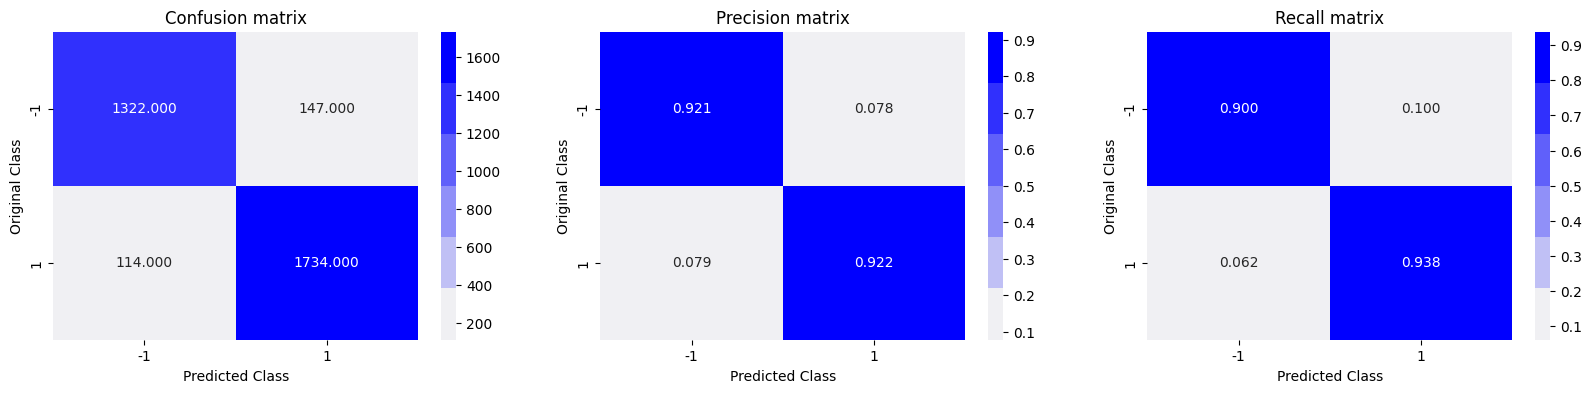

In [43]:
plot_confusion_matrix(test_Y, adc_predict)

Lets apply XGBoost Classifier and check its accuracy

In [44]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

In [45]:
train_Y_xgb = np.where(train_Y.to_numpy().ravel() == -1,0,1)
test_Y_xgb = np.where(test_Y.to_numpy().ravel() == -1,0,1)
xgb = XGBClassifier(random_state=42, eval_metric='logloss')
model_7 = xgb.fit(train_X, train_Y_xgb)

In [46]:
xgb_predict=model_7.predict(test_X)
xgb_predict_original = np.where(xgb_predict == 0, -1, 1)

In [47]:
print(" XGBoost Accuracy:", accuracy_score(test_Y, xgb_predict_original))
print(classification_report(test_Y, xgb_predict_original))

 XGBoost Accuracy: 0.9740729574917094
              precision    recall  f1-score   support

          -1       0.98      0.96      0.97      1469
           1       0.97      0.98      0.98      1848

    accuracy                           0.97      3317
   macro avg       0.97      0.97      0.97      3317
weighted avg       0.97      0.97      0.97      3317



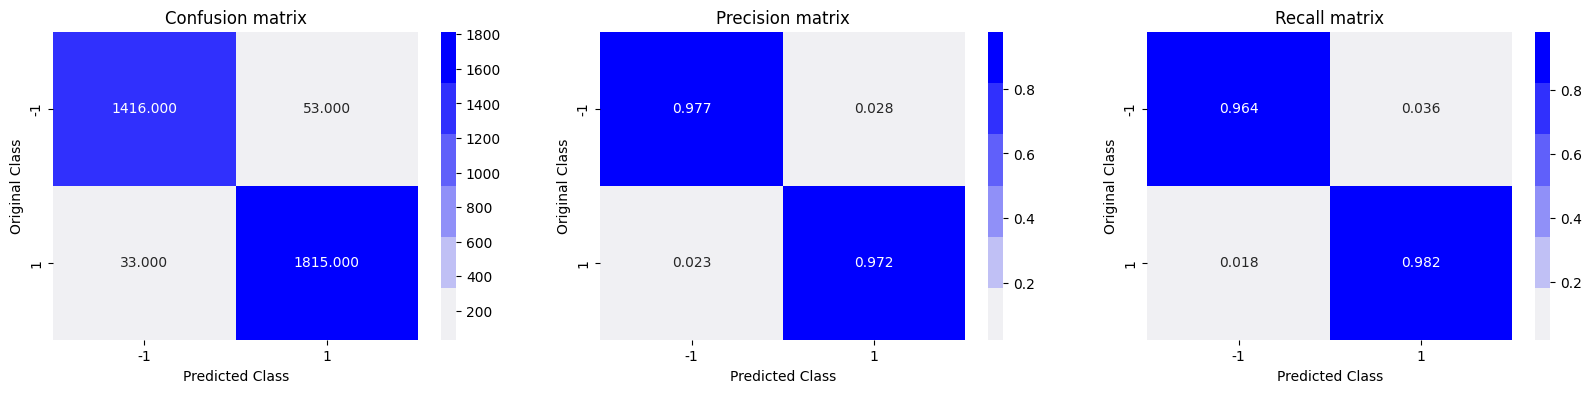

In [48]:
plot_confusion_matrix(test_Y, xgb_predict_original)

In [49]:
print('Logistic Regression Accuracy:',accuracy_score(logreg_predict,test_Y))
print('K-Nearest Neighbour Accuracy:',accuracy_score(knn_predict,test_Y))
print('Decision Tree Classifier Accuracy:',accuracy_score(dtree_predict,test_Y))
print('Random Forest Classifier Accuracy:',accuracy_score(rfc_predict,test_Y))
print('Adaboost Classifier Accuracy:',accuracy_score(adc_predict,test_Y))
print('XGBoost Accuracy:',accuracy_score(xgb_predict,test_Y_xgb))

Logistic Regression Accuracy: 0.9400060295447694
K-Nearest Neighbour Accuracy: 0.9445281881217968
Decision Tree Classifier Accuracy: 0.9602050045221586
Random Forest Classifier Accuracy: 0.9734700030147724
Adaboost Classifier Accuracy: 0.9213144407597227
XGBoost Accuracy: 0.9740729574917094


#Cross-validation results

In [50]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = { 'Logistic Regression ': logreg, 'K-Nearest Neighbour ': knn, 'Decision Tree Classifier ': dtree, 'Random Forest Classifier ': rfc, 'Adaboost Classifier ': adc, 'XGBoost ': xgb}

for name, model in models.items():
  if name == 'XGBoost ':
    y_cv = train_Y_xgb
  else:
    y_cv = train_Y

  scores = cross_val_score(model, train_X, y_cv, cv=cv, scoring='accuracy')
  print(name)
  print("CV scores:", scores)
  print("Mean Accuracy:", scores.mean())
  print("Standard Deviation:", scores.std())
  print("----------------------------")

Logistic Regression 
CV scores: [0.92312661 0.92248062 0.92049127 0.91273432 0.92889463]
Mean Accuracy: 0.9215454935701173
Standard Deviation: 0.005217899263908213
----------------------------
K-Nearest Neighbour 
CV scores: [0.93669251 0.9379845  0.94893342 0.93471235 0.93341952]
Mean Accuracy: 0.9383484580475006
Standard Deviation: 0.005521445004113708
----------------------------
Decision Tree Classifier 
CV scores: [0.95607235 0.9618863  0.95539754 0.95604396 0.95862961]
Mean Accuracy: 0.9576059523391945
Standard Deviation: 0.002409901139980617
----------------------------
Random Forest Classifier 
CV scores: [0.96447028 0.97674419 0.9741435  0.96832579 0.97155785]
Mean Accuracy: 0.971048323921101
Standard Deviation: 0.004311969157026588
----------------------------
Adaboost Classifier 
CV scores: [0.90568475 0.91731266 0.90950226 0.90820944 0.91467356]
Mean Accuracy: 0.9110765355635397
Standard Deviation: 0.004280134418603296
----------------------------
XGBoost 
CV scores: [0.963

In [51]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)

predictions = {'Logistic Regression': logreg_predict,'KNN': knn_predict,'Decision Tree': dtree_predict,'Random Forest': rfc_predict,'AdaBoost': adc_predict,'XGBoost': xgb_predict_original}

results = []

for name, pred in predictions.items():

    results.append({'Algorithm': name,'Accuracy': accuracy_score(test_Y, pred),'Precision': precision_score(test_Y, pred, average='weighted'),'Recall': recall_score(test_Y, pred, average='weighted'),'F1-score': f1_score(test_Y, pred, average='weighted')})

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by='Accuracy',ascending=False)
comparison_df.round(4)


,Algorithm,Accuracy,Precision,Recall,F1-score
5,XGBoost,0.9741,0.9741,0.9741,0.9741
3,Random Forest,0.9735,0.9735,0.9735,0.9734
2,Decision Tree,0.9602,0.9602,0.9602,0.9602
1,KNN,0.9445,0.9445,0.9445,0.9445
0,Logistic Regression,0.9400,0.9400,0.9400,0.9400
4,AdaBoost,0.9213,0.9213,0.9213,0.9212
